# Propensity Score Matcher

In this notebook, we show the basic usage of the PropensityScoreMatcher. The
propensity score [(Rosenbaum & Rubin, 1983)](https://doi.org/10.1093/biomet/70.1.41) is the probability of belonging to the target population given
baseline covariates:

\begin{equation}
e(x) = P(Z = 1 \mid X = x)
\end{equation}

where $X$ are the covariates and $Z = 1$ indicates membership in the target.
Patients are matched on similar estimated scores. 

Unlike the GeneticMatcher and
ConstraintSatisfactionMatcher, the PropensityScoreMatcher does not directly
optimize a particular balance score. Instead, it uses the given objective as a
measure of "correctness" of the propensity score model, tries a (possibly large)
number of potential models, and returns the one with the best score. In doing
this, we automate the often manual hyperparameter optimization that accompanies
propensity score matching. Because balance is not optimized directly, residual
imbalance often remains; see the linear program demo for how to improve upon a
propensity score match.


In [1]:
import logging 
logging.basicConfig(
    format="%(levelname)-4s [%(filename)s:%(lineno)d] %(message)s",
    level='INFO',
)

from pybalance.utils import *
from pybalance.sim import generate_toy_dataset
from pybalance.propensity import PropensityScoreMatcher, plot_propensity_score_distributions
from pybalance.visualization import (
    plot_numeric_features, 
    plot_categoric_features, 
    plot_binary_features,
    plot_joint_numeric_distributions,
    plot_per_feature_loss
)

In [2]:
m = generate_toy_dataset(n_pool=10000, n_target=1000, seed=123)
m

,age,height,weight,gender,haircolor,country,population,binary_0,binary_1,binary_2,binary_3,patient_id
0,60.807949,173.610298,77.912924,0.0,1,4,pool,0,0,1,1,0
1,45.810836,170.541198,112.416988,0.0,1,4,pool,0,1,0,0,1
2,58.876976,188.138610,108.789013,0.0,0,2,pool,0,0,1,1,2
3,73.398077,162.939196,65.345017,0.0,1,4,pool,0,1,1,1,3
4,56.890587,156.386701,78.140295,0.0,0,3,pool,0,0,1,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...
995,39.662026,162.692755,54.607476,0.0,2,4,target,0,0,1,1,10995
996,49.130301,141.583192,103.798145,1.0,0,2,target,1,0,0,0,10996
997,68.035281,168.744482,56.499644,1.0,1,1,target,0,0,0,1,10997
998,62.044564,177.796983,75.983973,1.0,1,1,target,0,0,0,1,10998


## Optimize Beta (Mean Absolute SMD)


Using the given objective function, search max_iter possible different propensity score models and take the model that gives the best match given that objective function.

In [3]:
# Note that using a caliper can result in matched population being 
# smaller than target! If this is undesired, do not use a caliper.
objective = beta = BetaBalance(m)
matcher = PropensityScoreMatcher(
    matching_data=m,
    objective=objective,
    time_limit=300,
    max_iter=100)
matcher.get_params()

{'objective': 'beta',
 'caliper': None,
 'max_iter': 100,
 'time_limit': 300,
 'method': 'greedy',
 'seed': None}

In [4]:
matcher.match()

INFO [matcher.py:259] Training model SGDClassifier (iter 1/100, 0.0 s) ...
INFO [matcher.py:219] Best propensity score match found:
INFO [matcher.py:220] 	Model: SGDClassifier
INFO [matcher.py:222] 	* alpha: 2.694299702619799
INFO [matcher.py:222] 	* class_weight: None
INFO [matcher.py:222] 	* early_stopping: False
INFO [matcher.py:222] 	* fit_intercept: False
INFO [matcher.py:222] 	* loss: log_loss
INFO [matcher.py:222] 	* max_iter: 1500
INFO [matcher.py:222] 	* penalty: elasticnet
INFO [matcher.py:223] 	Score (beta): 0.2423
INFO [matcher.py:224] 	Solution time: 0.1 s
INFO [matcher.py:259] Training model LogisticRegression (iter 2/100, 0.2 s) ...
INFO [matcher.py:219] Best propensity score match found:
INFO [matcher.py:220] 	Model: LogisticRegression
INFO [matcher.py:222] 	* C: 0.026513227933192572
INFO [matcher.py:222] 	* fit_intercept: False
INFO [matcher.py:222] 	* max_iter: 500
INFO [matcher.py:222] 	* penalty: l1
INFO [matcher.py:222] 	* solver: saga
INFO [matcher.py:223] 	Score 

,age,height,weight,gender,haircolor,country,population,binary_0,binary_1,binary_2,binary_3,patient_id
5781,74.382687,194.082038,118.760023,0.0,2,5,pool,1,0,0,0,5781
4759,50.782191,129.900068,66.654262,1.0,2,1,pool,1,0,1,1,4759
2288,47.530142,147.318246,59.861049,1.0,1,3,pool,0,1,0,1,2288
8223,46.656414,140.392554,65.453208,1.0,2,4,pool,1,0,0,1,8223
962,52.829914,137.725077,93.206007,0.0,1,2,pool,1,1,0,0,962
...,...,...,...,...,...,...,...,...,...,...,...,...
995,39.662026,162.692755,54.607476,0.0,2,4,target,0,0,1,1,10995
996,49.130301,141.583192,103.798145,1.0,0,2,target,1,0,0,0,10996
997,68.035281,168.744482,56.499644,1.0,1,1,target,0,0,0,1,10997
998,62.044564,177.796983,75.983973,1.0,1,1,target,0,0,0,1,10998


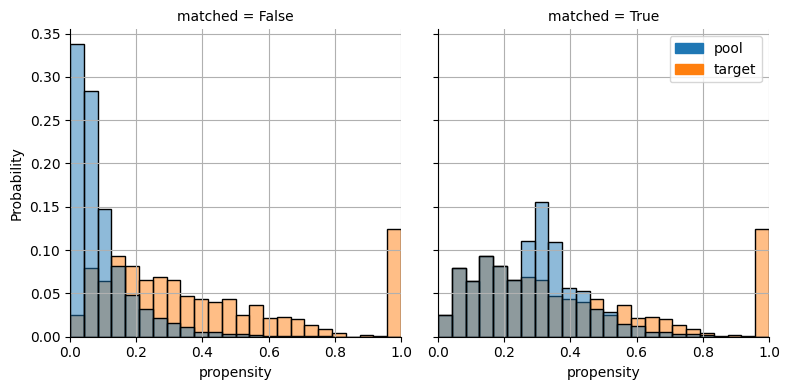

In [5]:
%matplotlib inline
plot_propensity_score_distributions(matcher)

INFO [matcher.py:219] Best propensity score match found:
INFO [matcher.py:220] 	Model: LogisticRegression
INFO [matcher.py:222] 	* C: 0.6191810056908827
INFO [matcher.py:222] 	* fit_intercept: False
INFO [matcher.py:222] 	* max_iter: 500
INFO [matcher.py:222] 	* penalty: l1
INFO [matcher.py:222] 	* solver: saga
INFO [matcher.py:223] 	Score (beta): 0.0310
INFO [matcher.py:224] 	Solution time: 8.7 s


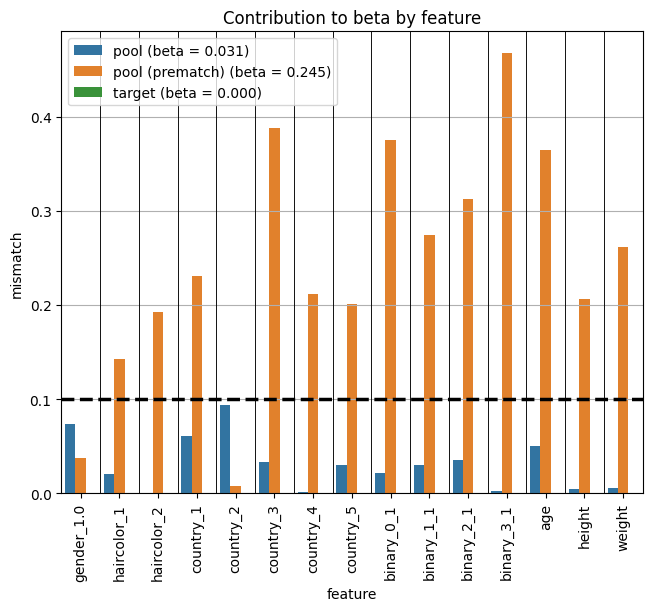

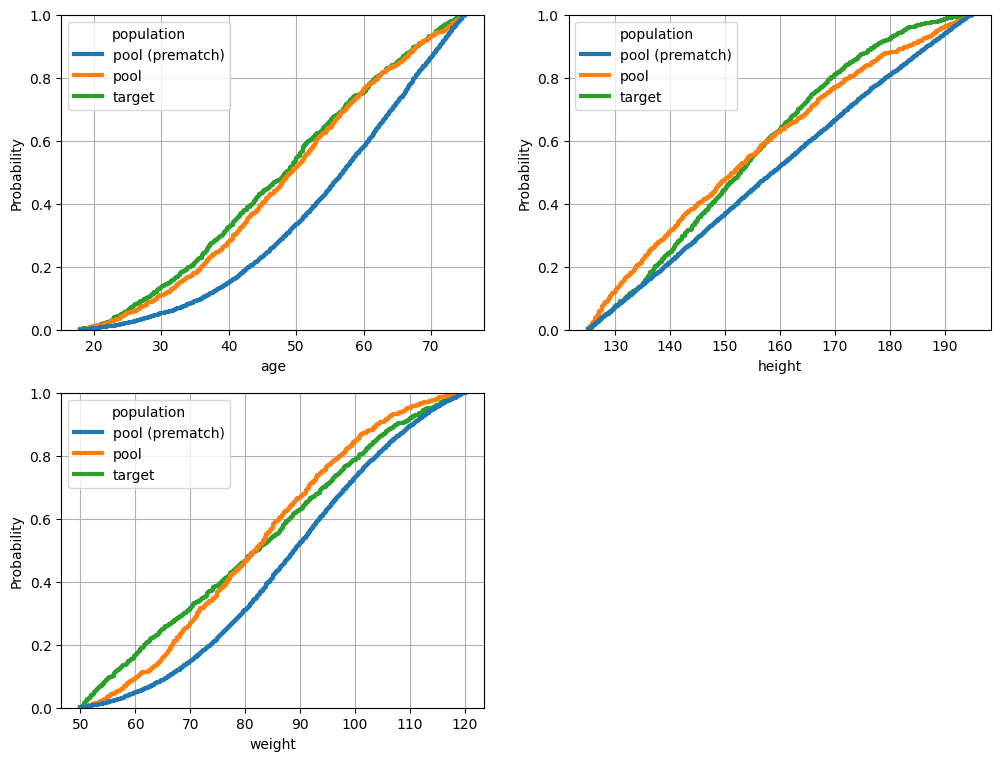

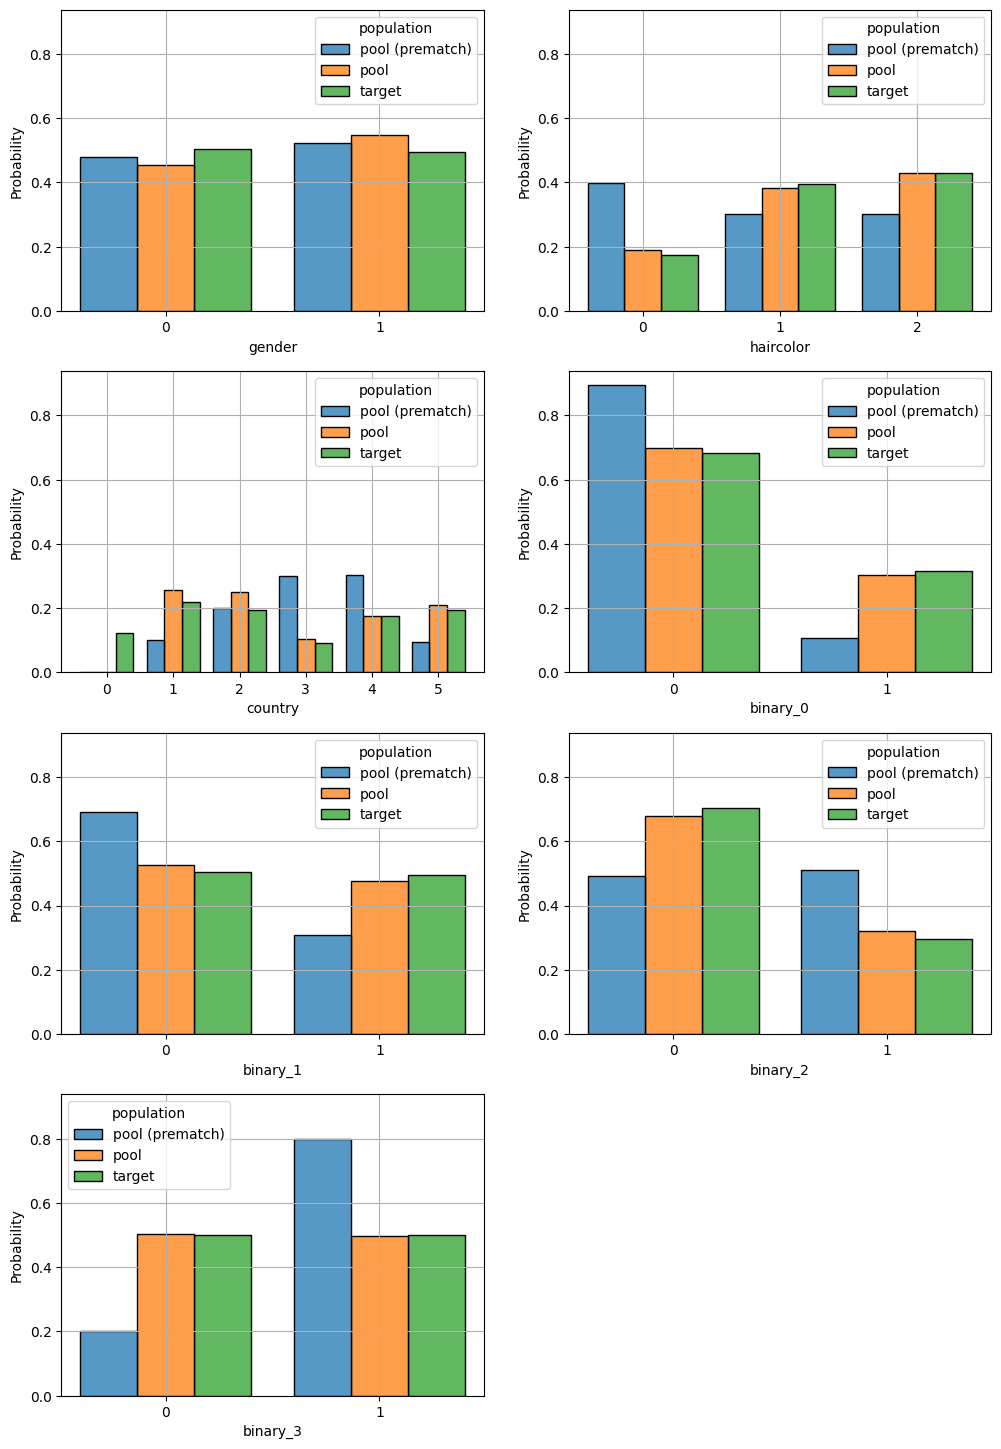

In [6]:
%matplotlib inline
objective = beta = BetaBalance(m)

match = matcher.get_best_match()
m_data = m.copy().get_population('pool')
m_data.loc[:, 'population'] = m_data['population'] + ' (prematch)'
match.append(m_data)
fig = plot_per_feature_loss(match, beta, 'target', debin=False)
fig = plot_numeric_features(match, hue_order=['pool (prematch)', 'pool', 'target', ])
fig = plot_categoric_features(match,  hue_order=['pool (prematch)', 'pool', 'target'])